<a href="https://colab.research.google.com/github/Rajapaksha-RMDD/pusl3123-ai-ml-coursework/blob/main/Exercise_3_Regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running Exercise 3 on: cuda:0


100%|██████████| 170M/170M [57:59<00:00, 49.0kB/s]



--- Starting Experiment: 1. CNN Baseline ---
Epoch [5/15] | Train Acc: 68.75% | Test Acc: 67.59%
Epoch [10/15] | Train Acc: 74.43% | Test Acc: 68.87%
Epoch [15/15] | Train Acc: 77.47% | Test Acc: 70.29%

--- Starting Experiment: 2. CNN + Dropout (0.25) ---
Epoch [5/15] | Train Acc: 66.04% | Test Acc: 65.69%
Epoch [10/15] | Train Acc: 70.07% | Test Acc: 69.29%
Epoch [15/15] | Train Acc: 72.59% | Test Acc: 70.28%

--- Starting Experiment: 3. CNN + Data Augmentation ---
Epoch [5/15] | Train Acc: 61.78% | Test Acc: 66.39%
Epoch [10/15] | Train Acc: 65.71% | Test Acc: 69.68%
Epoch [15/15] | Train Acc: 67.40% | Test Acc: 71.79%

Model Variant                | Train Acc  | Test Acc   | Gap (Train-Test)
-----------------------------------------------------------------
CNN Baseline                 |    77.47% |    70.29% |       7.18%
CNN + Dropout (0.25)         |    72.59% |    70.28% |       2.31%
CNN + Data Augmentation      |    67.40% |    71.79% |      -4.39%


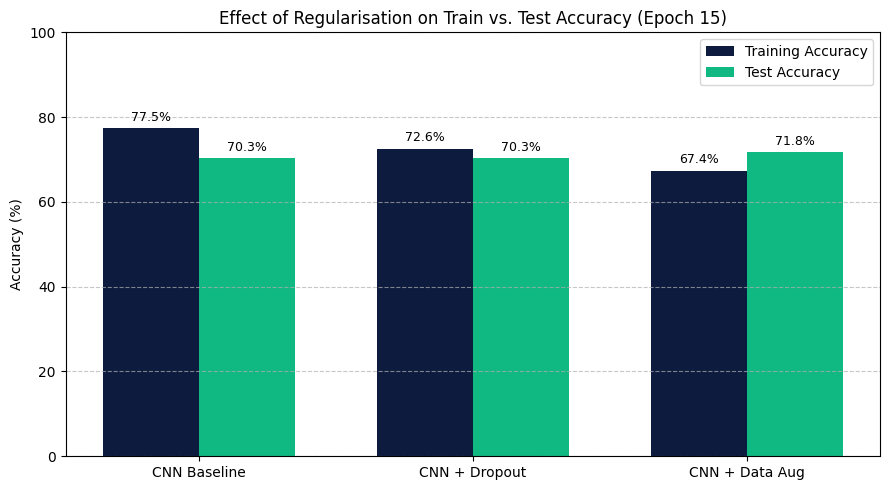

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Running Exercise 3 on: {device}")

# 1. Define Data Transformations
# Standard transform (for Baseline, Dropout, and all Test evaluations)
standard_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Augmented transform (for Training set in Experiment 3 only)
augmented_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)), # Small rotations & translations
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Load Datasets
trainset_standard = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=standard_transform)
trainset_augmented = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=augmented_transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=standard_transform)

trainloader_standard = torch.utils.data.DataLoader(trainset_standard, batch_size=64, shuffle=True, num_workers=2)
trainloader_augmented = torch.utils.data.DataLoader(trainset_augmented, batch_size=64, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

# 2. Define CNN Architecture with Optional Dropout
class RegularisedCNN(nn.Module):
    def __init__(self, use_dropout=False, dropout_rate=0.25):
        super(RegularisedCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.use_dropout = use_dropout
        self.dropout = nn.Dropout(p=dropout_rate)
        self.fc1 = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 8 * 8)
        if self.use_dropout:
            x = self.dropout(x)
        x = self.fc1(x)
        return x

# 3. Reusable Training & Evaluation Function
def run_experiment(name, model, train_loader, test_loader, epochs=15):
    print(f"\n--- Starting Experiment: {name} ---")
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_accs, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        correct_train, total_train = 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_train_acc = 100 * correct_train / total_train
        train_accs.append(epoch_train_acc)

        model.eval()
        correct_val, total_val = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        epoch_val_acc = 100 * correct_val / total_val
        val_accs.append(epoch_val_acc)

        if (epoch + 1) % 5 == 0 or epoch == epochs - 1:
            print(f"Epoch [{epoch+1}/{epochs}] | Train Acc: {epoch_train_acc:.2f}% | Test Acc: {epoch_val_acc:.2f}%")

    return train_accs, val_accs

# 4. Execute All Three Controlled Experiments
epochs = 15
base_train, base_val = run_experiment("1. CNN Baseline", RegularisedCNN(use_dropout=False), trainloader_standard, testloader, epochs)
drop_train, drop_val = run_experiment("2. CNN + Dropout (0.25)", RegularisedCNN(use_dropout=True, dropout_rate=0.25), trainloader_standard, testloader, epochs)
aug_train, aug_val   = run_experiment("3. CNN + Data Augmentation", RegularisedCNN(use_dropout=False), trainloader_augmented, testloader, epochs)

# 5. Summary Table Output for Report
print("\n" + "="*65)
print(f"{'Model Variant':<28} | {'Train Acc':<10} | {'Test Acc':<10} | {'Gap (Train-Test)'}")
print("-"*65)
for name, tr, te in [
    ("CNN Baseline", base_train[-1], base_val[-1]),
    ("CNN + Dropout (0.25)", drop_train[-1], drop_val[-1]),
    ("CNN + Data Augmentation", aug_train[-1], aug_val[-1])
]:
    print(f"{name:<28} | {tr:>8.2f}% | {te:>8.2f}% | {tr - te:>10.2f}%")
print("="*65)

# 6. Comparative Visualization
labels = ['CNN Baseline', 'CNN + Dropout', 'CNN + Data Aug']
final_train = [base_train[-1], drop_train[-1], aug_train[-1]]
final_test = [base_val[-1], drop_val[-1], aug_val[-1]]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, final_train, width, label='Training Accuracy', color='#0D1B3E')
rects2 = ax.bar(x + width/2, final_test, width, label='Test Accuracy', color='#10b981')

ax.set_ylabel('Accuracy (%)')
ax.set_title('Effect of Regularisation on Train vs. Test Accuracy (Epoch 15)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()